In [1]:

import pandas as pd

# Load all three CSV files
train = pd.read_csv("/content/train.csv")
test = pd.read_csv("/content/test.csv")
gender_submission = pd.read_csv("/content/gender_submission.csv")

# Display the first five rows
print("TRAIN DATASET")
display(train.head())

print("TEST DATASET")
display(test.head())

print("GENDER SUBMISSION DATASET")
display(gender_submission.head())

# Check dataset sizes
print("Train shape:", train.shape)
print("Test shape:", test.shape)
print("Gender submission shape:", gender_submission.shape)


TRAIN DATASET


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


TEST DATASET


,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,893,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S
2,894,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q
3,895,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S
4,896,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S


GENDER SUBMISSION DATASET


,PassengerId,Survived
0,892,0
1,893,1
2,894,0
3,895,0
4,896,1


Train shape: (891, 12)
Test shape: (418, 11)
Gender submission shape: (418, 2)


In [2]:

# Create a working copy
df_clean = train.copy()

# Check missing values
print(df_clean.isnull().sum())

# Check duplicate rows
print("Duplicate rows:", df_clean.duplicated().sum())

# View statistical summary
display(df_clean.describe(include="all"))


PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64
Duplicate rows: 0


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
count,891.000000,891.000000,891.000000,891,891,714.000000,891.000000,891.000000,891,891.000000,204,889
unique,NaN,NaN,NaN,891,2,NaN,NaN,NaN,681,NaN,147,3
top,NaN,NaN,NaN,"Dooley, Mr. Patrick",male,NaN,NaN,NaN,347082,NaN,G6,S
freq,NaN,NaN,NaN,1,577,NaN,NaN,NaN,7,NaN,4,644
mean,446.000000,0.383838,2.308642,NaN,NaN,29.699118,0.523008,0.381594,NaN,32.204208,NaN,NaN
std,257.353842,0.486592,0.836071,NaN,NaN,14.526497,1.102743,0.806057,NaN,49.693429,NaN,NaN
min,1.000000,0.000000,1.000000,NaN,NaN,0.420000,0.000000,0.000000,NaN,0.000000,NaN,NaN
25%,223.500000,0.000000,2.000000,NaN,NaN,20.125000,0.000000,0.000000,NaN,7.910400,NaN,NaN
50%,446.000000,0.000000,3.000000,NaN,NaN,28.000000,0.000000,0.000000,NaN,14.454200,NaN,NaN
75%,668.500000,1.000000,3.000000,NaN,NaN,38.000000,1.000000,0.000000,NaN,31.000000,NaN,NaN


In [4]:

# Create a copy for cleaning
df_clean = train.copy()

# Remove duplicate rows
df_clean = df_clean.drop_duplicates()

# Fill missing Age with median
df_clean["Age"] = df_clean["Age"].fillna(
    df_clean["Age"].median()
)

# Fill missing Embarked with mode
df_clean["Embarked"] = df_clean["Embarked"].fillna(
    df_clean["Embarked"].mode()[0]
)

# Fill missing Fare with median, if needed
df_clean["Fare"] = df_clean["Fare"].fillna(
    df_clean["Fare"].median()
)

# Add a column to identify whether cabin information exists
df_clean["CabinKnown"] = df_clean["Cabin"].notna()

print("Missing values after cleaning:")
print(df_clean.isnull().sum())

print("\nCleaned dataset shape:", df_clean.shape)


Missing values after cleaning:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age              0
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         0
CabinKnown       0
dtype: int64

Cleaned dataset shape: (891, 13)


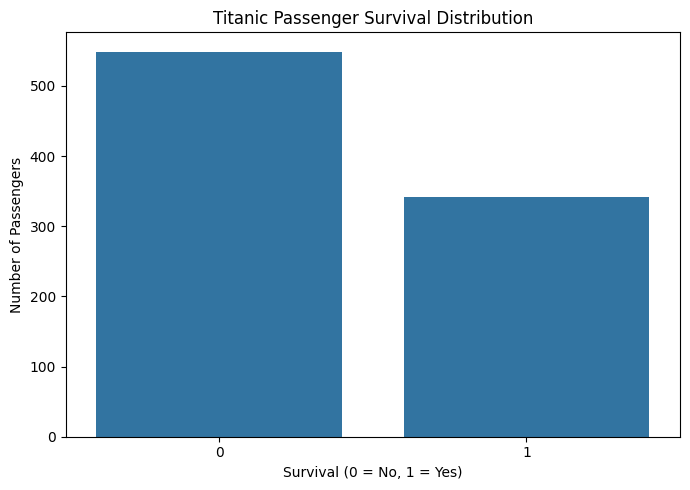

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))

sns.countplot(data=df_clean, x="Survived")

plt.title("Titanic Passenger Survival Distribution")
plt.xlabel("Survival (0 = No, 1 = Yes)")
plt.ylabel("Number of Passengers")

plt.tight_layout()
plt.savefig("survival_distribution.png", dpi=300)
plt.show()

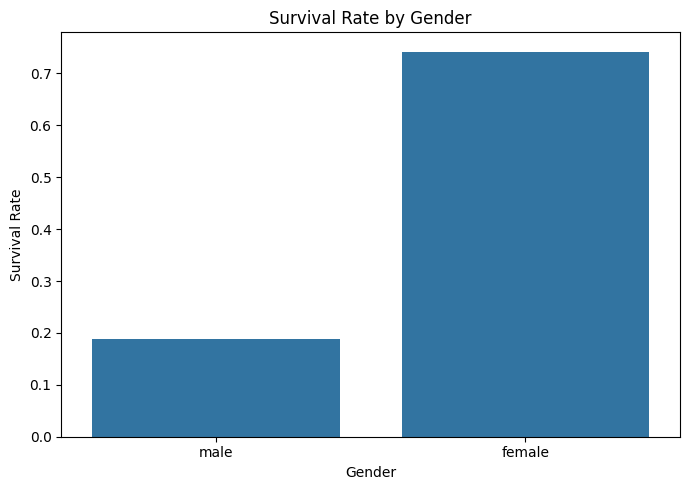

Sex
female    0.742038
male      0.188908
Name: Survived, dtype: float64


In [7]:

plt.figure(figsize=(7, 5))

sns.barplot(
    data=df_clean,
    x="Sex",
    y="Survived",
    errorbar=None
)

plt.title("Survival Rate by Gender")
plt.xlabel("Gender")
plt.ylabel("Survival Rate")

plt.tight_layout()
plt.savefig("survival_by_gender.png", dpi=300)
plt.show()

print(df_clean.groupby("Sex")["Survived"].mean())


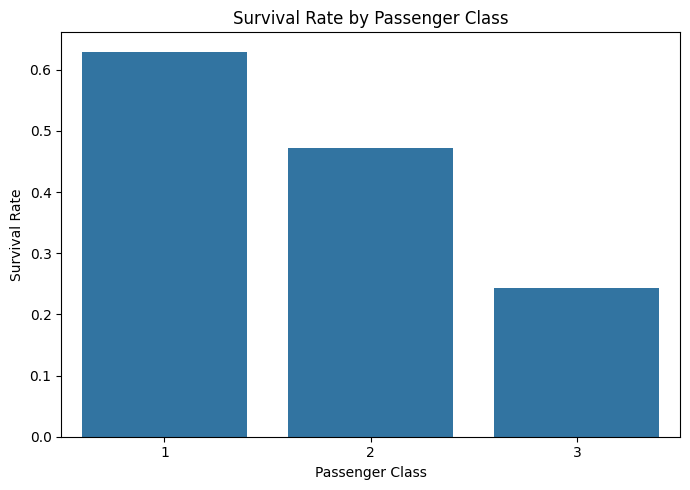

Pclass
1    0.629630
2    0.472826
3    0.242363
Name: Survived, dtype: float64


In [8]:

plt.figure(figsize=(7, 5))

sns.barplot(
    data=df_clean,
    x="Pclass",
    y="Survived",
    errorbar=None
)

plt.title("Survival Rate by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Survival Rate")

plt.tight_layout()
plt.savefig("survival_by_class.png", dpi=300)
plt.show()

print(df_clean.groupby("Pclass")["Survived"].mean())


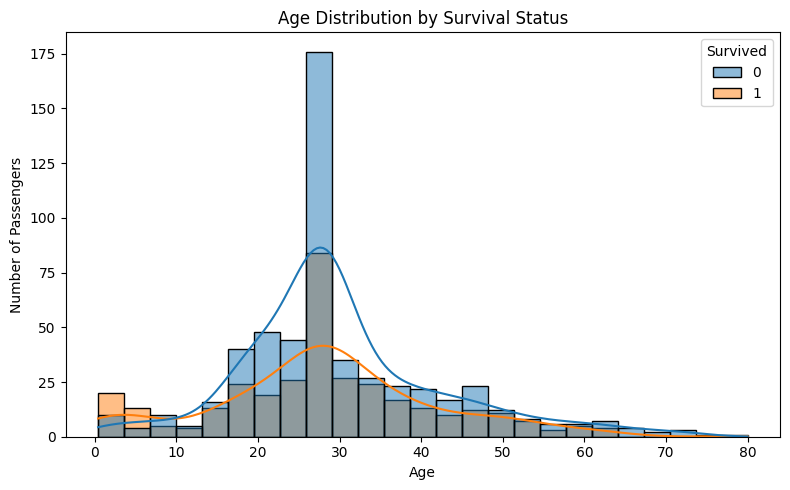

In [9]:

plt.figure(figsize=(8, 5))

sns.histplot(
    data=df_clean,
    x="Age",
    hue="Survived",
    bins=25,
    kde=True,
    multiple="layer"
)

plt.title("Age Distribution by Survival Status")
plt.xlabel("Age")
plt.ylabel("Number of Passengers")

plt.tight_layout()
plt.savefig("age_distribution.png", dpi=300)
plt.show()


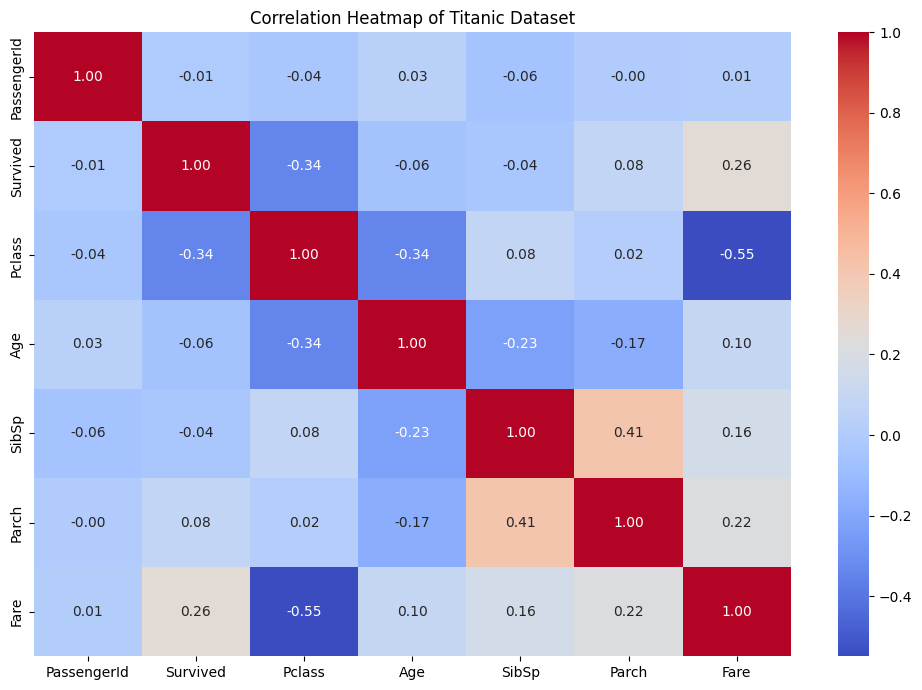

In [10]:

# Select numerical columns for correlation
numeric_df = df_clean.select_dtypes(include="number")

plt.figure(figsize=(10, 7))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap of Titanic Dataset")
plt.tight_layout()
plt.savefig("correlation_heatmap.png", dpi=300)
plt.show()


In [11]:

print("SURVIVAL RATE BY GENDER")
print(
    (df_clean.groupby("Sex")["Survived"].mean() * 100)
    .round(2)
)

print("\nSURVIVAL RATE BY PASSENGER CLASS")
print(
    (df_clean.groupby("Pclass")["Survived"].mean() * 100)
    .round(2)
)

print("\nAVERAGE AGE BY SURVIVAL STATUS")
print(
    df_clean.groupby("Survived")["Age"].mean().round(2)
)

print("\nOVERALL SURVIVAL RATE:")
print(round(df_clean["Survived"].mean() * 100, 2), "%")


SURVIVAL RATE BY GENDER
Sex
female    74.20
male      18.89
Name: Survived, dtype: float64

SURVIVAL RATE BY PASSENGER CLASS
Pclass
1    62.96
2    47.28
3    24.24
Name: Survived, dtype: float64

AVERAGE AGE BY SURVIVAL STATUS
Survived
0    30.03
1    28.29
Name: Age, dtype: float64

OVERALL SURVIVAL RATE:
38.38 %
